# WEEK 7 – DIMENSIONALITY REDUCTION

## Aim
To reduce the number of features in the dataset using
feature selection techniques and Principal Component Analysis (PCA).

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Week_6_Feature_Engineered_Dataset.csv to Week_6_Feature_Engineered_Dataset.csv


In [ ]:
import pandas as pd

df = pd.read_csv('Week_6_Feature_Engineered_Dataset.csv')

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (785640, 77)


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,...,"schedule_Part-time, Temp work, and Internship",schedule_Pekerjaan tetap,schedule_Per diem,schedule_Temp work,schedule_Temp work and Full-time,schedule_Temp work and Internship,"schedule_Temp work, Full-time, and Part-time",schedule_Volunteer,salary_year_log,salary_hour_log
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,...,0,0,0,0,0,0,0,0,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,...,0,0,0,0,0,0,0,0,NaN,NaN
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,...,0,0,0,0,0,0,0,0,NaN,NaN
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,...,0,0,0,0,0,0,0,0,NaN,NaN
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,...,0,0,0,0,0,0,0,0,NaN,NaN


## 1. Numerical Feature Identification

In this step, we identify the numerical columns in the feature-engineered dataset. These numerical features will be examined and selected for dimensionality reduction using PCA.

In [ ]:
# Identify numerical columns
numeric_columns = df.select_dtypes(include=['number']).columns

print("Numerical Features:")
print(numeric_columns.tolist())

print("\nTotal Numerical Features:", len(numeric_columns))

Numerical Features:
['salary_year_avg', 'salary_hour_avg', 'posted_year', 'posted_month', 'posted_day', 'year_scaled', 'month_scaled', 'day_scaled', 'year_standard', 'month_standard', 'day_standard', 'schedule_Contractor', 'schedule_Contractor and Full-time', 'schedule_Contractor and Internship', 'schedule_Contractor and Part-time', 'schedule_Contractor and Per diem', 'schedule_Contractor and Temp work', 'schedule_Contractor, Temp work, and Internship', 'schedule_Full-time', 'schedule_Full-time and Contractor', 'schedule_Full-time and Internship', 'schedule_Full-time and Part-time', 'schedule_Full-time and Per diem', 'schedule_Full-time and Temp work', 'schedule_Full-time and Volunteer', 'schedule_Full-time, Contractor, and Internship', 'schedule_Full-time, Contractor, and Temp work', 'schedule_Full-time, Contractor, and Volunteer', 'schedule_Full-time, Part-time, and Contractor', 'schedule_Full-time, Part-time, and Internship', 'schedule_Full-time, Part-time, and Per diem', 'schedule_

In [ ]:
# Check missing values
print(df[numeric_columns].isnull().sum())

salary_year_avg                                 763638
salary_hour_avg                                 774978
posted_year                                          0
posted_month                                         0
posted_day                                           0
                                                 ...  
schedule_Temp work and Internship                    0
schedule_Temp work, Full-time, and Part-time         0
schedule_Volunteer                                   0
salary_year_log                                 763638
salary_hour_log                                 774978
Length: 61, dtype: int64


In [ ]:
# Display columns that contain missing values
missing_values = df[numeric_columns].isnull().sum()

missing_columns = missing_values[missing_values > 0]

print("Columns with Missing Values:")
print(missing_columns)

print("\nTotal Columns with Missing Values:", len(missing_columns))

Columns with Missing Values:
salary_year_avg    763638
salary_hour_avg    774978
salary_year_log    763638
salary_hour_log    774978
dtype: int64

Total Columns with Missing Values: 4


In [ ]:
# Exclude salary columns from PCA
exclude_columns = [
    'salary_year_avg',
    'salary_hour_avg',
    'salary_year_log',
    'salary_hour_log'
]

# Select remaining numerical features
pca_features = [
    col for col in numeric_columns
    if col not in exclude_columns
]

# Create PCA dataset
pca_df = df[pca_features].copy()

print("PCA Dataset Shape:", pca_df.shape)
print("\nMissing Values:", pca_df.isnull().sum().sum())
print("\nSelected Features:")
print(pca_features)

PCA Dataset Shape: (785640, 57)

Missing Values: 0

Selected Features:
['posted_year', 'posted_month', 'posted_day', 'year_scaled', 'month_scaled', 'day_scaled', 'year_standard', 'month_standard', 'day_standard', 'schedule_Contractor', 'schedule_Contractor and Full-time', 'schedule_Contractor and Internship', 'schedule_Contractor and Part-time', 'schedule_Contractor and Per diem', 'schedule_Contractor and Temp work', 'schedule_Contractor, Temp work, and Internship', 'schedule_Full-time', 'schedule_Full-time and Contractor', 'schedule_Full-time and Internship', 'schedule_Full-time and Part-time', 'schedule_Full-time and Per diem', 'schedule_Full-time and Temp work', 'schedule_Full-time and Volunteer', 'schedule_Full-time, Contractor, and Internship', 'schedule_Full-time, Contractor, and Temp work', 'schedule_Full-time, Contractor, and Volunteer', 'schedule_Full-time, Part-time, and Contractor', 'schedule_Full-time, Part-time, and Internship', 'schedule_Full-time, Part-time, and Per diem

In [ ]:
# Remove original and Min-Max scaled date columns
columns_to_drop = [
    'posted_year',
    'posted_month',
    'posted_day',
    'year_scaled',
    'month_scaled',
    'day_scaled'
]

pca_df = pca_df.drop(columns=columns_to_drop)

print("Updated PCA Dataset Shape:", pca_df.shape)
print("\nMissing Values:", pca_df.isnull().sum().sum())
print("\nRemaining Features:")
print(pca_df.columns.tolist())

Updated PCA Dataset Shape: (785640, 51)

Missing Values: 0

Remaining Features:
['year_standard', 'month_standard', 'day_standard', 'schedule_Contractor', 'schedule_Contractor and Full-time', 'schedule_Contractor and Internship', 'schedule_Contractor and Part-time', 'schedule_Contractor and Per diem', 'schedule_Contractor and Temp work', 'schedule_Contractor, Temp work, and Internship', 'schedule_Full-time', 'schedule_Full-time and Contractor', 'schedule_Full-time and Internship', 'schedule_Full-time and Part-time', 'schedule_Full-time and Per diem', 'schedule_Full-time and Temp work', 'schedule_Full-time and Volunteer', 'schedule_Full-time, Contractor, and Internship', 'schedule_Full-time, Contractor, and Temp work', 'schedule_Full-time, Contractor, and Volunteer', 'schedule_Full-time, Part-time, and Contractor', 'schedule_Full-time, Part-time, and Internship', 'schedule_Full-time, Part-time, and Per diem', 'schedule_Full-time, Part-time, and Temp work', 'schedule_Full-time, Part-time

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardize all selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_df)

print("Scaled Dataset Shape:", X_scaled.shape)
print("Mean of first 5 features:", X_scaled.mean(axis=0)[:5])
print("Standard deviation of first 5 features:", X_scaled.std(axis=0)[:5])

Scaled Dataset Shape: (785640, 51)
Mean of first 5 features: [0.00000000e+00 4.22541579e-17 8.79993485e-18 5.64353479e-18
 8.09449301e-19]
Standard deviation of first 5 features: [0. 1. 1. 1. 1.]


In [ ]:
from sklearn.feature_selection import VarianceThreshold

# Remove features with zero variance
selector = VarianceThreshold(threshold=0)

X_selected = selector.fit_transform(X_scaled)

# Get selected feature names
selected_features = pca_df.columns[selector.get_support()]

print("Original Features:", X_scaled.shape[1])
print("Features After Selection:", X_selected.shape[1])
print("Removed Features:", X_scaled.shape[1] - X_selected.shape[1])
print("\nSelected Features:")
print(selected_features.tolist())

Original Features: 51
Features After Selection: 50
Removed Features: 1

Selected Features:
['month_standard', 'day_standard', 'schedule_Contractor', 'schedule_Contractor and Full-time', 'schedule_Contractor and Internship', 'schedule_Contractor and Part-time', 'schedule_Contractor and Per diem', 'schedule_Contractor and Temp work', 'schedule_Contractor, Temp work, and Internship', 'schedule_Full-time', 'schedule_Full-time and Contractor', 'schedule_Full-time and Internship', 'schedule_Full-time and Part-time', 'schedule_Full-time and Per diem', 'schedule_Full-time and Temp work', 'schedule_Full-time and Volunteer', 'schedule_Full-time, Contractor, and Internship', 'schedule_Full-time, Contractor, and Temp work', 'schedule_Full-time, Contractor, and Volunteer', 'schedule_Full-time, Part-time, and Contractor', 'schedule_Full-time, Part-time, and Internship', 'schedule_Full-time, Part-time, and Per diem', 'schedule_Full-time, Part-time, and Temp work', 'schedule_Full-time, Part-time, and 

In [ ]:
from sklearn.decomposition import PCA

# Apply PCA with 2 components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_selected)

print("PCA Dataset Shape:", X_pca.shape)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(sum(pca.explained_variance_ratio_) * 100, "%")

PCA Dataset Shape: (785640, 2)

Explained Variance Ratio:
[0.03858011 0.02353159]

Total Explained Variance:
6.211169178848365 %


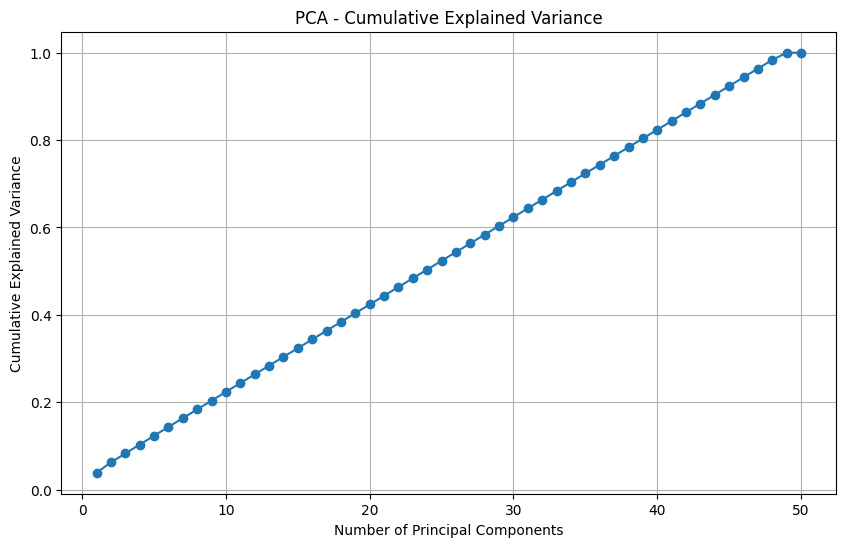

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Calculate PCA for all selected features
pca_full = PCA()
pca_full.fit(X_selected)

# Calculate cumulative explained variance
cumulative_variance = pca_full.explained_variance_ratio_.cumsum()

# Plot explained variance
plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')
plt.grid(True)
plt.show()

In [ ]:
import numpy as np

# Find components required for 80% and 90% variance
components_80 = np.argmax(cumulative_variance >= 0.80) + 1
components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print("Components required for 80% variance:", components_80)
print("Components required for 90% variance:", components_90)

print("\nVariance retained with 80% components:",
      cumulative_variance[components_80 - 1] * 100, "%")

print("Variance retained with 90% components:",
      cumulative_variance[components_90 - 1] * 100, "%")

Components required for 80% variance: 39
Components required for 90% variance: 44

Variance retained with 80% components: 80.37033280457713 %
Variance retained with 90% components: 90.37034948876654 %


In [ ]:
# Apply PCA with 80% variance retention
pca_80 = PCA(n_components=0.80)

X_pca_80 = pca_80.fit_transform(X_selected)

print("Original Dataset Shape:", X_selected.shape)
print("Reduced Dataset Shape:", X_pca_80.shape)

print("\nNumber of Components:", pca_80.n_components_)
print("Total Explained Variance:",
      sum(pca_80.explained_variance_ratio_) * 100, "%")

Original Dataset Shape: (785640, 50)
Reduced Dataset Shape: (785640, 39)

Number of Components: 39
Total Explained Variance: 80.37033280457713 %


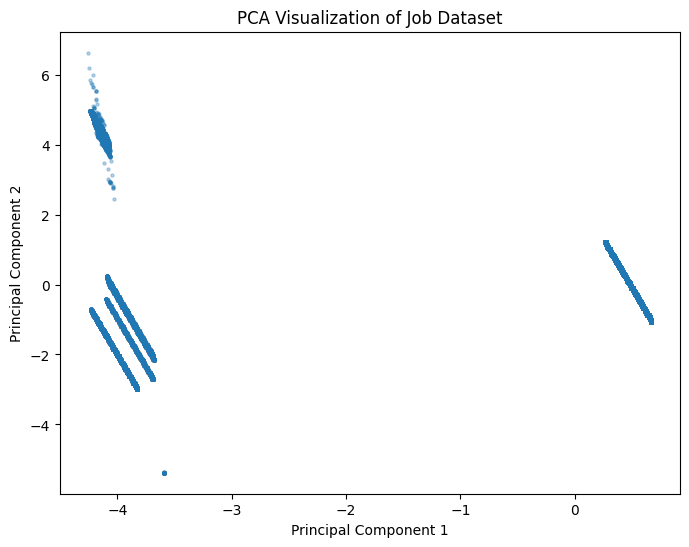

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.3,
    s=5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Job Dataset")

plt.show()

In [ ]:
# Create PCA output DataFrame
pca_result_df = pd.DataFrame(
    X_pca_80,
    columns=[f'PC{i+1}' for i in range(X_pca_80.shape[1])]
)

print("Final PCA Dataset:")
print(pca_result_df.head())

print("\nFinal Dataset Shape:", pca_result_df.shape)

Final PCA Dataset:
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0  0.485308 -0.010924 -0.002947 -0.005481 -0.015329  0.029214 -0.020584   
1  0.659222 -0.977996  0.062545  0.026940  0.026970 -0.035845  0.049945   
2  0.352972  0.715118 -0.066052  0.035985  0.170810 -0.339797  0.232449   
3  0.461612  0.104802 -0.033522  0.098007  0.335123 -0.644762  0.470212   
4  0.424505  0.314506 -0.042956  0.068464  0.251407 -0.487705  0.350240   

        PC8       PC9      PC10  ...      PC30      PC31      PC32      PC33  \
0  0.000567  0.000408 -0.002047  ...  0.000031  0.000014 -0.000024 -0.000008   
1  0.000729 -0.000752  0.003421  ... -0.000195 -0.000435  0.000448  0.000114   
2 -0.006806 -0.004660  0.023440  ... -0.000384  0.000250 -0.000365 -0.000271   
3 -0.011284 -0.009144  0.045580  ... -0.000895 -0.000096 -0.000058 -0.000301   
4 -0.008838 -0.006861  0.034271  ... -0.000646  0.000035 -0.000165 -0.000270   

       PC34          PC35          PC36          

In [ ]:
# Save PCA dataset
pca_result_df.to_csv(
    'Week_7_PCA_Reduced_Dataset.csv',
    index=False
)

print("PCA Dataset saved successfully!")

PCA Dataset saved successfully!


In [ ]:
from google.colab import files

files.download('Week_7_PCA_Reduced_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>